In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração estética dos gráficos
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
import warnings
warnings.filterwarnings('ignore')

print("Ambiente configurado!")


Ambiente configurado!


In [2]:
def gerar_dados_eda(n_samples=10000):
    np.random.seed(42)
    
    # 1. Gerar Classes (Desbalanceadas: 3% de Fraude)
    n_frauds = int(n_samples * 0.03)
    n_legit = n_samples - n_frauds
    classes = np.concatenate([np.zeros(n_legit), np.ones(n_frauds)])
    
    # 2. Hora do Dia (0 a 24h)
    # Legítimos: Distribuição normal centrada no almoço (13h) e noite (19h)
    hours_legit = np.concatenate([
        np.random.normal(13, 3, size=n_legit // 2),
        np.random.normal(19, 4, size=n_legit // 2)
    ])
    
    # Fraudes: Focadas na madrugada (Média 03:00 da manhã)
    hours_fraud = np.random.normal(3, 1.5, size=n_frauds)
    
    hours = np.concatenate([hours_legit, hours_fraud])
    hours = np.mod(hours, 24) # Garante que fique entre 0 e 24
    
    # 3. Valor da Transação
    # Fraudes tentam valores mais altos para maximizar o roubo
    amount_legit = np.random.exponential(50, size=n_legit)
    amount_fraud = np.random.exponential(250, size=n_frauds)
    amounts = np.concatenate([amount_legit, amount_fraud])
    
    # 4. Velocidade do Mouse (Comportamento)
    # Fraudes (Bots) são extremamente rápidas ou perfeitamente lineares
    mouse_speed_legit = np.random.normal(0.5, 0.2, size=n_legit)
    mouse_speed_fraud = np.random.normal(0.95, 0.05, size=n_frauds) # Muito rápido
    mouse_speeds = np.concatenate([mouse_speed_legit, mouse_speed_fraud])
    
    # Criar DataFrame
    df = pd.DataFrame({
        'hora_do_dia': hours,
        'valor_transacao': amounts,
        'velocidade_mouse': mouse_speeds,
        'is_fraud': classes.astype(int)
    })
    
    return df

df = gerar_dados_eda()
print(f"Dataset gerado com {len(df)} transações.")
display(df.head())


Dataset gerado com 10000 transações.


,hora_do_dia,valor_transacao,velocidade_mouse,is_fraud
0,14.490142,19.375501,0.404108,0
1,12.585207,5.436041,0.294386,0
2,14.943066,3.725809,0.600400,0
3,17.569090,4.951032,0.158627,0
4,12.297540,43.717791,0.446432,0


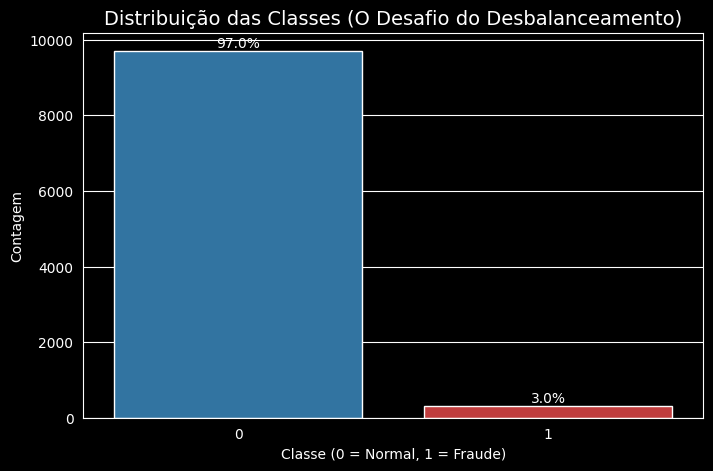

In [ ]:
plt.style.use('dark_background')

plt.figure(figsize=(8, 5))
ax = sns.countplot(x='is_fraud', data=df, palette=['#1f77b4', '#d62728'])

plt.title('Distribuição das Classes (O Desafio do Desbalanceamento)', fontsize=14)
plt.xlabel('Classe (0 = Normal, 1 = Fraude)')
plt.ylabel('Contagem')

# Adicionar porcentagens nas barras
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%\n' # type: ignore
    x = p.get_x() + p.get_width() / 2 # type: ignore
    y = p.get_height() # type: ignore
    ax.annotate(percentage, (x, y), ha='center', va='center')

plt.show()


Como podemos ver, apenas 3% dos dados são fraudes. Isso justifica minha escolha futura de usar métricas como Recall e F1-Score em vez de Acurácia, e o uso do parâmetro class_weight='balanced' no Random Forest

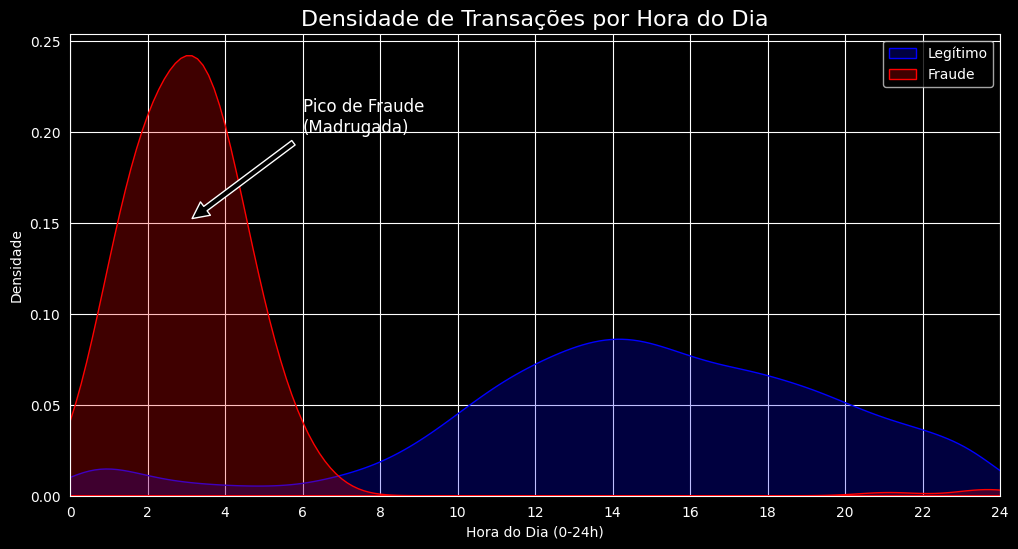

In [ ]:
plt.figure(figsize=(12, 6))

# KDE Plot (Density) permite ver a sobreposição das distribuições
sns.kdeplot(data=df[df['is_fraud'] == 0]['hora_do_dia'], label='Legítimo', shade=True, color='blue') # type: ignore
sns.kdeplot(data=df[df['is_fraud'] == 1]['hora_do_dia'], label='Fraude', shade=True, color='red') # type: ignore

plt.title('Densidade de Transações por Hora do Dia', fontsize=16)
plt.xlabel('Hora do Dia (0-24h)')
plt.ylabel('Densidade')
plt.xlim(0, 24)
plt.xticks(range(0, 25, 2)) # Marcações a cada 2 horas
plt.legend()

plt.annotate('Pico de Fraude\n(Madrugada)', xy=(3, 0.15), xytext=(6, 0.2),
             arrowprops=dict(facecolor='black', shrink=0.05), fontsize=12)

plt.show()


A hipótese se confirmou. Enquanto usuários normais operam em horário comercial e início da noite, vemos um pico claro (curva vermelha) por volta das 03:00 da manhã. Isso sugere que uma feature is_dawn (é_madrugada) seria muito poderosa para o modelo.

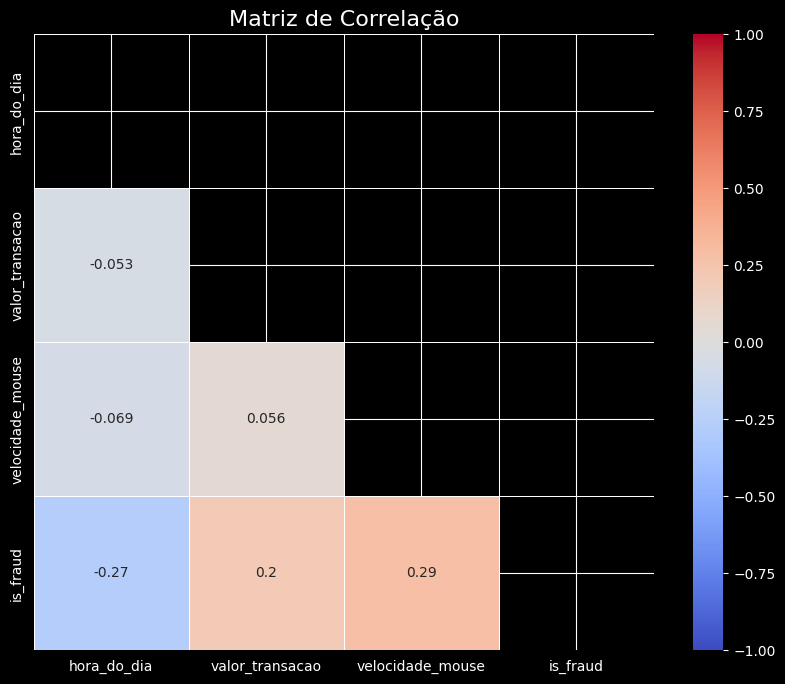

In [5]:
plt.figure(figsize=(10, 8))

# Calculando a correlação de Spearman (melhor para dados não-lineares/monetários)
corr = df.corr(method='spearman')

mask = np.triu(np.ones_like(corr, dtype=bool)) # Esconde a parte superior duplicada

sns.heatmap(corr, mask=mask, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0, linewidths=.5)
plt.title('Matriz de Correlação', fontsize=16)
plt.show()


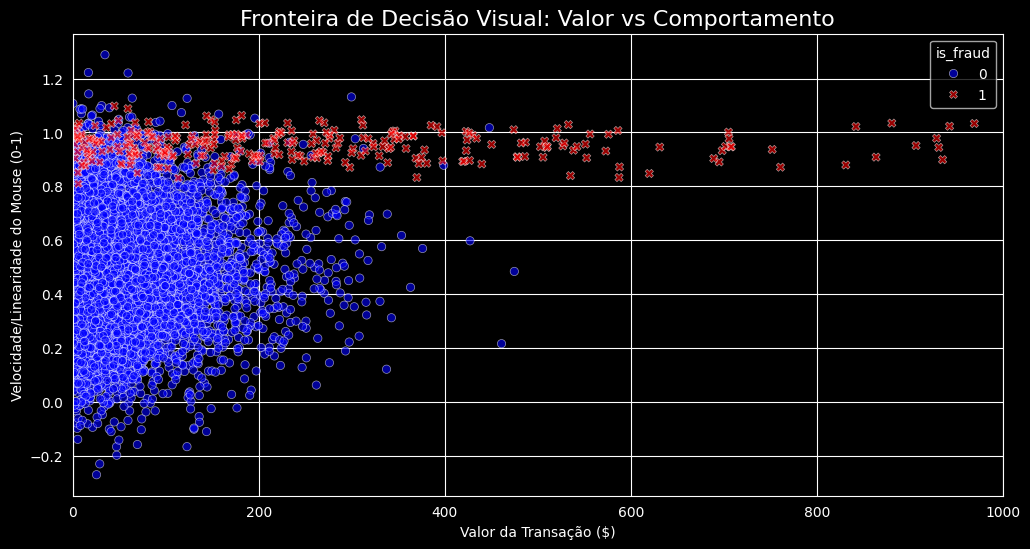

In [6]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df, 
    x='valor_transacao', 
    y='velocidade_mouse', 
    hue='is_fraud', 
    palette={0: 'blue', 1: 'red'},
    alpha=0.6,
    style='is_fraud' # Diferencia também pelo formato do ponto
)

plt.title('Fronteira de Decisão Visual: Valor vs Comportamento', fontsize=16)
plt.xlabel('Valor da Transação ($)')
plt.ylabel('Velocidade/Linearidade do Mouse (0-1)')

# Limitando o eixo X para melhor visualização (remove outliers extremos de valor)
plt.xlim(0, 1000) 
plt.show()


Percebam como os pontos vermelhos se aglomeram no topo (alta velocidade de mouse) e tendem a ter valores mais altos (mais para a direita). O modelo consegue traçar uma linha aqui para separar esses grupos.

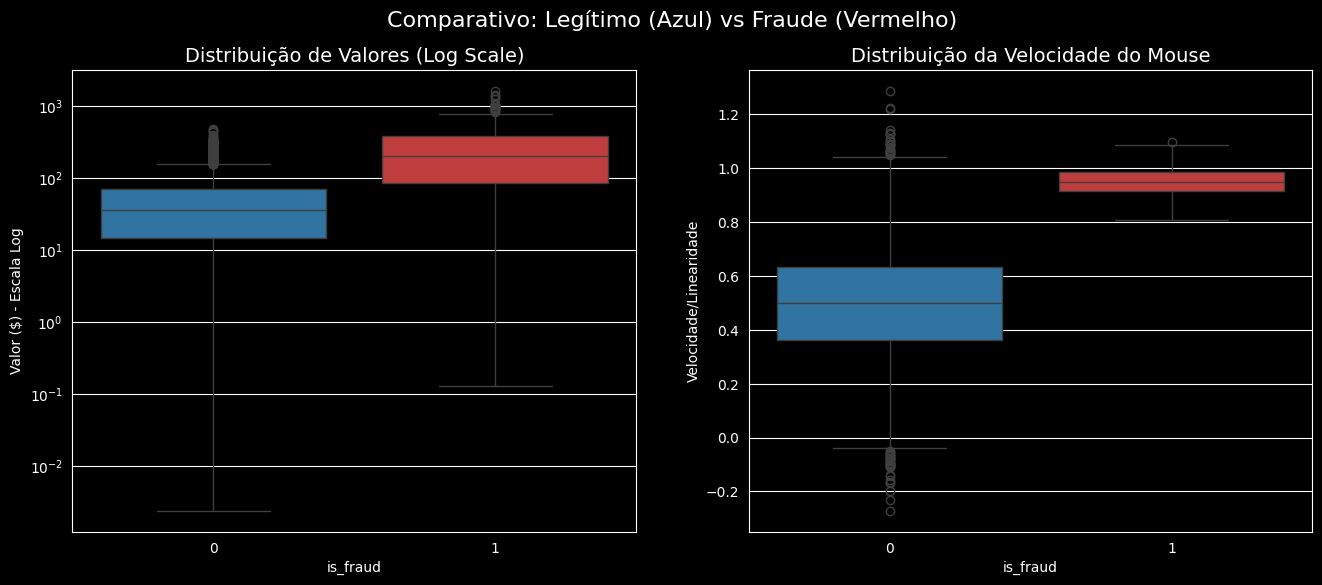

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Comparação Financeira
# Usamos escala logarítmica (yscale='log') porque valores financeiros variam muito (de R$ 10 a R$ 10.000)
sns.boxplot(x='is_fraud', y='valor_transacao', data=df, palette=['#1f77b4', '#d62728'], ax=axes[0])
axes[0].set_title('Distribuição de Valores (Log Scale)', fontsize=14)
axes[0].set_ylabel('Valor ($) - Escala Log')
axes[0].set_yscale('log') # Truque visual para ver melhor quando há muita diferença

# Gráfico 2: Comparação Comportamental
sns.boxplot(x='is_fraud', y='velocidade_mouse', data=df, palette=['#1f77b4', '#d62728'], ax=axes[1])
axes[1].set_title('Distribuição da Velocidade do Mouse', fontsize=14)
axes[1].set_ylabel('Velocidade/Linearidade')

plt.suptitle('Comparativo: Legítimo (Azul) vs Fraude (Vermelho)', fontsize=16)
plt.show()


## A "Caixa" (IQR):

A caixa representa 50% dos usuários. Note como a caixa vermelha no gráfico da direita (Mouse) está muito mais 'apertada' e alta. Isso prova que fraudadores (robôs) têm um comportamento muito repetitivo e padronizado, enquanto humanos (caixa azul) variam muito mais.

## A Mediana (A linha dentro da caixa):

A linha preta central mostra que, tipicamente, o fraudador tenta transações de valor mediano mais alto que o cliente comum.

## Os Pontos (Outliers):

Os pontos acima dos 'bigodes' (whiskers) são os outliers. No gráfico de valores, vemos muitos pontos azuis altos. Isso é importante: **existem clientes legítimos ricos que gastam muito**. Se criarmos uma regra simples 'bloquear valor > 500', vamos bloquear esses clientes VIPs (Falsos Positivos). Por isso precisamos do modelo de ML e não apenas regras de if/else.